<img src="img/ost_logo.png" width="240" align="right"/>
<div style="text-align: left"> <b> Applied Nueral Networks: Projekt </b> <br> FS 2026 <br> <a href="mailto:ryan.mikus@ost.ch"> Ryan Mikus </a> und <a href="mailto:ilija.amato@ost.ch"> Ilija Amato </a> </div>

<div style="text-align: center; border: 3px solid red; border-radius: 8px; padding: 16px 24px; margin: 16px 0; background-color: #fff5f5; max-width: 100%; box-sizing: border-box; word-wrap: break-word;">
  <p style="color: red; font-size: 1.5em; font-weight: bold; margin: 0 0 8px 0;">⚠️ Achtung: Veraltete Version</p>
  <p style="color: #cc0000; font-size: 0.9em; margin: 0;">
    Diese Version hat einen methodisch falschen Trainingsansatz: Die Zeitschritte werden als unabhängige Samples in zufällig gemischten Batches trainiert, wobei der Reservoir-Zustand pro Batch auf null zurückgesetzt wird. Dadurch geht das zeitliche Gedächtnis des Reservoirs verloren und <strong>W_out</strong> lernt nur lokale Input-Output-Mappings ohne Kontext — der eigentliche Vorteil des ESN wird nicht genutzt. Die neue Version sammelt die Reservoir-Zustände stattdessen sequenziell, sodass jeder Zustand die gesamte Geschichte der Schwingung enthält. Diese Version ist nur für Diskussionszwecke noch vorhanden.
  </p>
</div>

# Training: Echo State Network mit PyTorch

---

## Was ist Reservoir Computing?

Ein **Echo State Network (ESN)** ist eine spezielle Klasse rekurrenter neuronaler Netze, die für die Verarbeitung von **Zeitreihen** entwickelt wurde. Im Gegensatz zu klassischen RNNs oder LSTMs wird beim ESN das interne Netzwerk (das sog. *Reservoir*) **zufällig initialisiert und danach nicht mehr verändert**. Nur die Ausgabeschicht wird trainiert.

### Warum ist das sinnvoll?

Bei klassischen RNNs muss das gesamte Netz, inklusive aller rekurrenten Verbindungen, durch Backpropagation trainiert werden. Das führt zu drei bekannten Problemen:

- **Vanishing Gradient**: der Gradient wird über viele Zeitschritte exponentiell klein und das Netz lernt kaum noch
- **Langsames Training**: jeder Parameter jeder Schicht muss angepasst werden
- **Lokale Minima**: das Optimierungsproblem ist nichtkonvex, der Optimizer kann in suboptimalen Lösungen stecken bleiben

Das ESN umgeht alle drei Probleme.

Trainiert wird nur die **Ausgabeschicht `W_out`**. Das ist eine einfache lineare Regression:

- konvex: garantiert globales Minimum
- schnell: nur eine Schicht, keine Zeitschritte rückwärts
- stabil: kein Vanishing Gradient möglich

### Grundprinzip

**Schritt 1: Eingabe transformieren**  
Der aktuelle Messwert `u(t)` wird über die zufällige, fixe Matrix `W_in` auf N Reservoir-Neuronen projiziert.

**Schritt 2: Gedächtnis aufbauen**  
Gleichzeitig fliesst der alte Reservoir-Zustand `x(t-1)` über die rekurrente Matrix `W` zurück. Dadurch enthält `x(t)` eine nichtlineare Mischung aller bisherigen Eingaben und das Reservoir baut ein **Gedächtnis** auf.

**Schritt 3: Zustand aktualisieren**  
Beide Anteile werden kombiniert und durch `tanh` auf `[-1, 1]` begrenzt:

$$x(t) = \tanh\bigl(W_{in} \cdot u(t) + W \cdot x(t-1)\bigr)$$

**Schritt 4: Vorhersage ausgeben**  
Die trainierbare Ausgabeschicht `W_out` liest den Zustand `x(t)` aus und liefert die Vorhersage für den nächsten Zeitschritt:

$$y(t+1) = W_{out} \cdot x(t) + b$$

**Schritt 5: Nur `W_out` wird trainiert**  
`W_in` und `W` bleiben während des gesamten Trainings unverändert. Das Modell lernt lediglich, welche Linearkombination der N Reservoir-Zustände die beste Vorhersage liefert — mathematisch eine konvexe lineare Regression ohne Vanishing-Gradient-Problem.

- **`W_in`**: projiziert den skalaren Input auf N Reservoir-Neuronen (fix, zufällig)
- **`W`**: rekurrente Verbindungen im Reservoir (fix, dünn besetzt)
- **`W_out`**: lernbare Ausgabeschicht (nur diese wird trainiert)

### Aufbau dieses Notebooks

1. Imports & Daten laden
2. Dataset und DataLoader
3. ESN als `nn.Module` implementieren
4. Training mit MSE Loss und Adam Optimizer
5. Auswertung auf Testdaten
6. Hyperparameter-Suche: Optimale Reservoir-Grösse
7. Zusammenfassung


## 1. Imports und Daten laden

### Verwendete Bibliotheken

| Bibliothek | Wozu |
|---|---|
| `numpy` | Array-Operationen, Datei-I/O |
| `matplotlib` | Visualisierungen |
| `torch` | Tensor-Berechnungen, Autograd |
| `torch.nn` | Netzwerk-Bausteine (Linear, Module, Loss) |
| `torch.utils.data` | Dataset- und DataLoader-Infrastruktur |

### Gerät (Device)

PyTorch kann Berechnungen auf der **CPU** oder einer **GPU** (CUDA) ausführen. Mit `torch.device('cuda' if torch.cuda.is_available() else 'cpu')` wird automatisch die schnellste verfügbare Option gewählt. Alle Tensoren und Modelle müssen auf dasselbe Gerät verschoben werden (`.to(device)`), sonst entstehen Laufzeitfehler.

### Reproduzierbarkeit

`torch.manual_seed(42)` und `np.random.seed(42)` setzen den Zufallszahlengenerator auf einen fixen Wert. So sind die zufälligen Reservoir-Gewichte bei jedem Durchlauf identisch   wichtig für vergleichbare Experimente.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

# Gerät festlegen: GPU wenn vorhanden, sonst CPU
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Verwendetes Gerät: {device}")

# Reproduzierbarkeit
torch.manual_seed(42)
np.random.seed(42)

# Daten aus Notebook 01 laden
train_data = np.load('data/train_clean.npy',    allow_pickle=True)
test_data  = np.load('data/test_clean_id.npy',  allow_pickle=True)

print(f"Trainingsdaten: {len(train_data)} Schwingungen")
print(f"Testdaten:      {len(test_data)} Schwingungen")


Verwendetes Gerät: cpu
Trainingsdaten: 25 Schwingungen
Testdaten:      25 Schwingungen


## 2. Dataset und DataLoader

### PyTorch-Dateninfrastruktur

PyTorch trennt sauber zwischen *wie ein Sample aussieht* (`Dataset`) und *wie Samples an das Netz geliefert werden* (`DataLoader`):

```
Rohdaten  →  Dataset.__getitem__(idx)  →  DataLoader (Batches, Shuffle)  →  Training
```

- **`Dataset`**   definiert ein einzelnes Sample: hier ein Paar `(y(t), y(t+1))`
- **`DataLoader`**   liefert Batches, mischt die Reihenfolge (`shuffle=True`)

### One-Step-Ahead-Prediction

Das Ziel ist: gegeben `y(t)`, vorhersage `y(t+1)`.
Aus einer Schwingung `[y₀, y₁, ..., y_T]` entstehen `T` unabhängige Samples:

```
t=0: Input=y₀  →  Target=y₁
t=1: Input=y₁  →  Target=y₂
...
t=T-1: Input=y_{T-1}  →  Target=y_T
```

**Wichtig:** Im Training werden die Samples als **unabhängig** behandelt. Der Reservoir-Zustand `x` wird pro Batch zurückgesetzt. Nur bei der Auswertung (Abschnitt 5) wird der Zustand sequenziell weitergegeben.

### `unsqueeze(0)`

Jeder Wert `y(t)` ist ein Skalar (0-dimensional). `unsqueeze(0)` fügt eine Dimension hinzu → Form `(1,)`. Der DataLoader stapelt dann Batches zu Form `(batch, 1)`.


In [2]:
class OscillationDataset(Dataset):
    def __init__(self, oscillations):
        self.samples = []
        for osc in oscillations:
            y = torch.tensor(osc['y'], dtype=torch.float32)
            for t in range(len(y) - 1):
                # unsqueeze(0): Skalar → Vektor der Laenge 1, fuer Batch-Kompatibilitaet
                self.samples.append((y[t].unsqueeze(0), y[t+1].unsqueeze(0)))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        return self.samples[idx]


train_dataset = OscillationDataset(train_data)
test_dataset  = OscillationDataset(test_data)

train_loader = DataLoader(train_dataset, batch_size=256, shuffle=True)
test_loader  = DataLoader(test_dataset,  batch_size=256, shuffle=False)

print(f"Trainings-Samples: {len(train_dataset)}")
print(f"Test-Samples:      {len(test_dataset)}")
print(f"Batches pro Epoche: {len(train_loader)}")


Trainings-Samples: 24975
Test-Samples:      24975
Batches pro Epoche: 98


## 3. Echo State Network als `nn.Module`

### Architektur-Überblick

| Komponente | Typ | Form | Trainierbar? |
|---|---|---|---|
| `W_in` | `register_buffer` | `(N, 1)` | Nein |
| `W` | `register_buffer` | `(N, N)` | Nein |
| `W_out` | `nn.Linear(N, 1)` | `(1, N)` + Bias | **Ja** |

### `register_buffer` vs. `nn.Parameter`

- **`nn.Parameter`**: wird von PyTorch als trainierbarer Parameter registriert, erscheint in `model.parameters()` und bekommt Gradienten
- **`register_buffer`**: ist Teil des Modells (wird gespeichert und auf das Device verschoben), bekommt aber **keinen Gradient** und erscheint nicht in `model.parameters()`

Das Reservoir `W` und `W_in` werden als Buffer registriert: Sie sind fix und sollen nicht durch Backpropagation verändert werden.

### Spectral Radius

Der **Spektralradius** ist der grösste Betrag aller Eigenwerte von `W`. Er kontrolliert das *Echo State Property*:

- **< 1**: Eingaben vergessen sich exponentiell, kurzes Gedächtnis
- **≈ 1**: Grenze der Stabilität, langes Gedächtnis
- **> 1**: Reservoir divergiert (instabil)

Typisch: `0.8 – 0.99`. In diesem Notebook: `0.95`.

### Sparsity

Nur ein Bruchteil der Reservoir-Gewichte ist von Null verschieden. `sparsity=0.1` bedeutet: 10% der Verbindungen sind aktiv, 90% sind Null. Dies ahmt die sparse Konnektivität biologischer Netze nach und verbessert oft die Generalisierung.

### Forward-Pass (ein Zeitschritt)

```
x(t) = tanh( W_in · u(t)  +  W · x(t-1) )
                ↑ Input-Anteil    ↑ Rekurrenter Anteil (Gedächtnis)

y(t+1) = W_out · x(t) + bias
```

Die `tanh`-Aktivierung begrenzt den Zustand auf `[-1, 1]` und verhindert, dass das Reservoir explodiert.


In [3]:
class EchoStateNetwork(nn.Module):

    def __init__(self, n_reservoir=300, spectral_radius=0.9, sparsity=0.1, verbose=True):
        super().__init__()
        self.n_reservoir = n_reservoir

        # --- Eingabe-Gewichte W_in (fix) ---
        W_in = torch.empty(n_reservoir, 1).uniform_(-1, 1)
        self.register_buffer('W_in', W_in)

        # --- Reservoir-Gewichte W (fix, sparse) ---
        W = torch.empty(n_reservoir, n_reservoir).uniform_(-1, 1)
        self.W: torch.Tensor
        mask = torch.rand_like(W) > sparsity
        W[mask] = 0.0
        eigenvalues = torch.linalg.eigvals(W)
        current_radius = eigenvalues.abs().max()
        W = W * (spectral_radius / current_radius.item())
        self.register_buffer('W', W)

        # --- Ausgabeschicht W_out (trainierbar) ---
        self.W_out = nn.Linear(n_reservoir, 1)

        if verbose:
            trainable = sum(p.numel() for p in self.parameters() if p.requires_grad)
            total     = sum(p.numel() for p in self.parameters()) + sum(b.numel() for b in self.buffers())
            print(f"ESN: {n_reservoir} Neuronen | Trainierbar: {trainable} / {total} Parameter")

    def forward(self, u, x=None):
        batch = u.shape[0]
        if x is None:
            x = torch.zeros(batch, self.n_reservoir, device=u.device)

        # x(t) = tanh( W_in * u(t) + W * x(t-1) )
        x = torch.tanh(
            u @ self.W_in.T +
            x @ self.W.T
        )

        # y(t+1) = W_out * x(t)
        y = self.W_out(x)
        return y, x


# Standard-Modell fuer Abschnitte 4 & 5
model = EchoStateNetwork(n_reservoir=300, spectral_radius=0.95, sparsity=0.1).to(device)


ESN: 300 Neuronen | Trainierbar: 301 / 90601 Parameter


## 4. Training

### Loss-Funktion: MSE

Der **Mean Squared Error** (mittlerer quadratischer Fehler) misst die durchschnittliche quadratische Abweichung zwischen Vorhersage `ŷ` und Zielwert `y`:

$$\text{MSE} = \frac{1}{B} \sum_{i=1}^{B} (\hat{y}_i - y_i)^2$$

Quadrieren bestraft grosse Fehler stärker als kleine.


### Training-Schleife

```
Für jede Epoche:
  Für jeden Batch (u, target):
    1. Vorwärtspass: pred = model(u)        ← forward() aufgerufen
    2. Loss berechnen: L = MSE(pred, target)
    3. Gradienten nullen: optimizer.zero_grad()
    4. Rückwärtspass: loss.backward()       ← Gradient nur durch W_out
    5. Update: optimizer.step()             ← nur W_out wird verändert
```

**Wichtig:** Da nur `W_out` trainierbar ist, fliesst der Gradient ausschliesslich durch die lineare Ausgabeschicht   das Reservoir `W` und `W_in` bleiben unverändert.

### Test-Loss: Abgleich mit ungesehenen Daten

Nach jeder Trainings-Epoche wird das Modell zusätzlich auf den **Testdaten** ausgewertet. Dabei gelten zwei wichtige Regeln:

**`model.eval()`** schaltet das Modell in den Auswertungsmodus. Das deaktiviert Mechanismen wie Dropout, die nur beim Training aktiv sein sollen.

**`torch.no_grad()`** deaktiviert das Autograd-System vollständig   PyTorch baut keinen Berechnungsgraphen auf, da keine Gradienten benötigt werden. Das spart Speicher und beschleunigt die Auswertung.

Das Modell lernt **ausschliesslich** aus den Trainingsdaten. Die Testdaten dienen nur zur Kontrolle, sie werden nie für `loss.backward()` oder `optimizer.step()` verwendet.

### Visualisierung: Zwei Plots

**Plot 1   Train- und Test-Loss über Epochen:**  
Beide Kurven sollten fallen und sich einem Plateau annähern.

**Plot 2   Differenz `Test-Loss − Train-Loss`:**  
Diese Kurve zeigt direkt, ob das Modell **overfittet**:

| Differenz | Bedeutung |
|---|---|
| ≈ 0 | Modell generalisiert gut   kein Overfitting |
| dauerhaft > 0 | Test schlechter als Train → Overfitting |
| dauerhaft < 0 | Test besser als Train → Testdaten "einfacher" |

### Warum Train ≈ Test beim ESN?

Ein ESN trainiert nur `W_out`   das sind **301 Parameter** bei 24'975 Trainingssamples:

$$\frac{\text{Datenpunkte}}{\text{Parameter}} = \frac{24975}{301} \approx 83\times$$

Das System ist massiv **überbestimmt** (viel mehr Daten als Parameter). Overfitting ist bei linearer Regression in diesem Regime praktisch unmöglich   daher bleibt die Differenz nahe null. Das ist kein Fehler, sondern ein Vorteil des ESN-Ansatzes.


Epoche  1/50  Train: 0.019205  Test: 0.009771
Epoche  2/50  Train: 0.015405  Test: 0.008720
Epoche  3/50  Train: 0.014652  Test: 0.008472
Epoche  4/50  Train: 0.014482  Test: 0.008319
Epoche  5/50  Train: 0.014440  Test: 0.008592
Epoche  6/50  Train: 0.014574  Test: 0.008767
Epoche  7/50  Train: 0.014356  Test: 0.008296
Epoche  8/50  Train: 0.014531  Test: 0.008296
Epoche  9/50  Train: 0.014427  Test: 0.008335
Epoche 10/50  Train: 0.014552  Test: 0.008324
Epoche 11/50  Train: 0.014533  Test: 0.008460
Epoche 12/50  Train: 0.014538  Test: 0.008475
Epoche 13/50  Train: 0.014560  Test: 0.008397
Epoche 14/50  Train: 0.014643  Test: 0.008313
Epoche 15/50  Train: 0.014632  Test: 0.008388
Epoche 16/50  Train: 0.014439  Test: 0.009026
Epoche 17/50  Train: 0.014505  Test: 0.008324
Epoche 18/50  Train: 0.014499  Test: 0.008375
Epoche 19/50  Train: 0.014397  Test: 0.008340
Epoche 20/50  Train: 0.014461  Test: 0.008375
Epoche 21/50  Train: 0.014542  Test: 0.008410
Epoche 22/50  Train: 0.014496  Tes

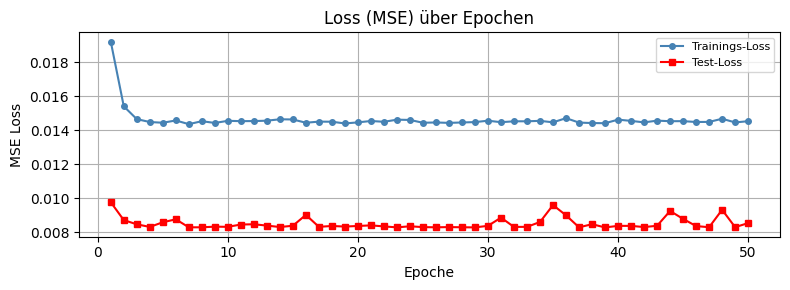

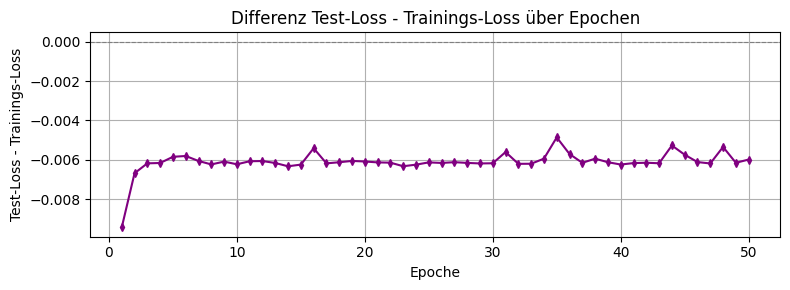

In [4]:
torch.manual_seed(42)
np.random.seed(42)

criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

N_EPOCHS = 50
train_losses = []
test_losses  = []
differences  = []

for epoch in range(N_EPOCHS):
    # --- Training ---
    model.train()
    epoch_loss = 0.0
    for u_batch, target_batch in train_loader:
        u_batch      = u_batch.to(device)
        target_batch = target_batch.to(device)
        pred, _ = model(u_batch)
        loss = criterion(pred, target_batch)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()

    # --- Test-Loss ---
    model.eval()
    epoch_loss_test = 0.0
    with torch.no_grad():
        for u_batch, target_batch in test_loader:
            u_batch      = u_batch.to(device)
            target_batch = target_batch.to(device)
            pred, _ = model(u_batch)
            epoch_loss_test += criterion(pred, target_batch).item()

    avg_loss      = epoch_loss      / len(train_loader)
    avg_loss_test = epoch_loss_test / len(test_loader)
    train_losses.append(avg_loss)
    test_losses.append(avg_loss_test)
    differences.append(avg_loss_test - avg_loss)
    print(f"Epoche {epoch+1:2d}/{N_EPOCHS}  Train: {avg_loss:.6f}  Test: {avg_loss_test:.6f}")

plt.figure(figsize=(8, 3))
plt.plot(range(1, N_EPOCHS+1), train_losses, marker='o', markersize=4, color='steelblue', label='Trainings-Loss')
plt.plot(range(1, N_EPOCHS+1), test_losses,  marker='s', markersize=4, color='red',       label='Test-Loss')
plt.legend(loc='upper right', fontsize=8)
plt.title('Loss (MSE) über Epochen')
plt.xlabel('Epoche')
plt.ylabel('MSE Loss')
plt.grid(True)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 3))
plt.plot(range(1, N_EPOCHS+1), differences, marker='d', markersize=4, color='purple')
plt.axhline(0, color='gray', linewidth=0.8, linestyle='--')
plt.title('Differenz Test-Loss - Trainings-Loss über Epochen')
plt.xlabel('Epoche')
plt.ylabel('Test-Loss - Trainings-Loss')
plt.grid(True)
plt.tight_layout()
plt.show()


## 5. Auswertung auf Testdaten

### Sequenzielle Inferenz

Im Training wurden Zeitschritte als unabhängige Samples behandelt. Bei der **Auswertung** lassen wir das Modell die Schwingung sequenziell durchlaufen: Der Reservoir-Zustand `x` wird von Schritt zu Schritt **weitergereicht**. So kann das ESN sein zeitliches Gedächtnis nutzen.

```
t=0: u=y₀, x=0    → pred₀, x₁
t=1: u=y₁, x=x₁   → pred₁, x₂
...
t=T: u=y_T, x=x_T → pred_T, x_{T+1}
```

### Warmup-Phase

Die ersten `WARMUP=100` Zeitschritte werden **ignoriert**. In dieser Phase "erwärmt" sich das Reservoir: Der Zustand `x` konvergiert von Null zu einem informationstragenden Zustand, der die bisherige Eingabe reflektiert. Vorhersagen in dieser Phase wären unzuverlässig.

### Fehlermetrik: RMSE

Der **Root Mean Squared Error** ist die Wurzel des MSE, er hat dieselbe Einheit wie die Zielgrösse und ist intuitiver interpretierbar:

$$\text{RMSE} = \sqrt{\frac{1}{N}\sum_{t=1}^{N}(\hat{y}_t - y_t)^2}$$

### `torch.no_grad()`

Bei der Auswertung werden **keine Gradienten** benötigt. `torch.no_grad()` deaktiviert das Autograd-System → weniger Speicher, schnellere Ausführung.


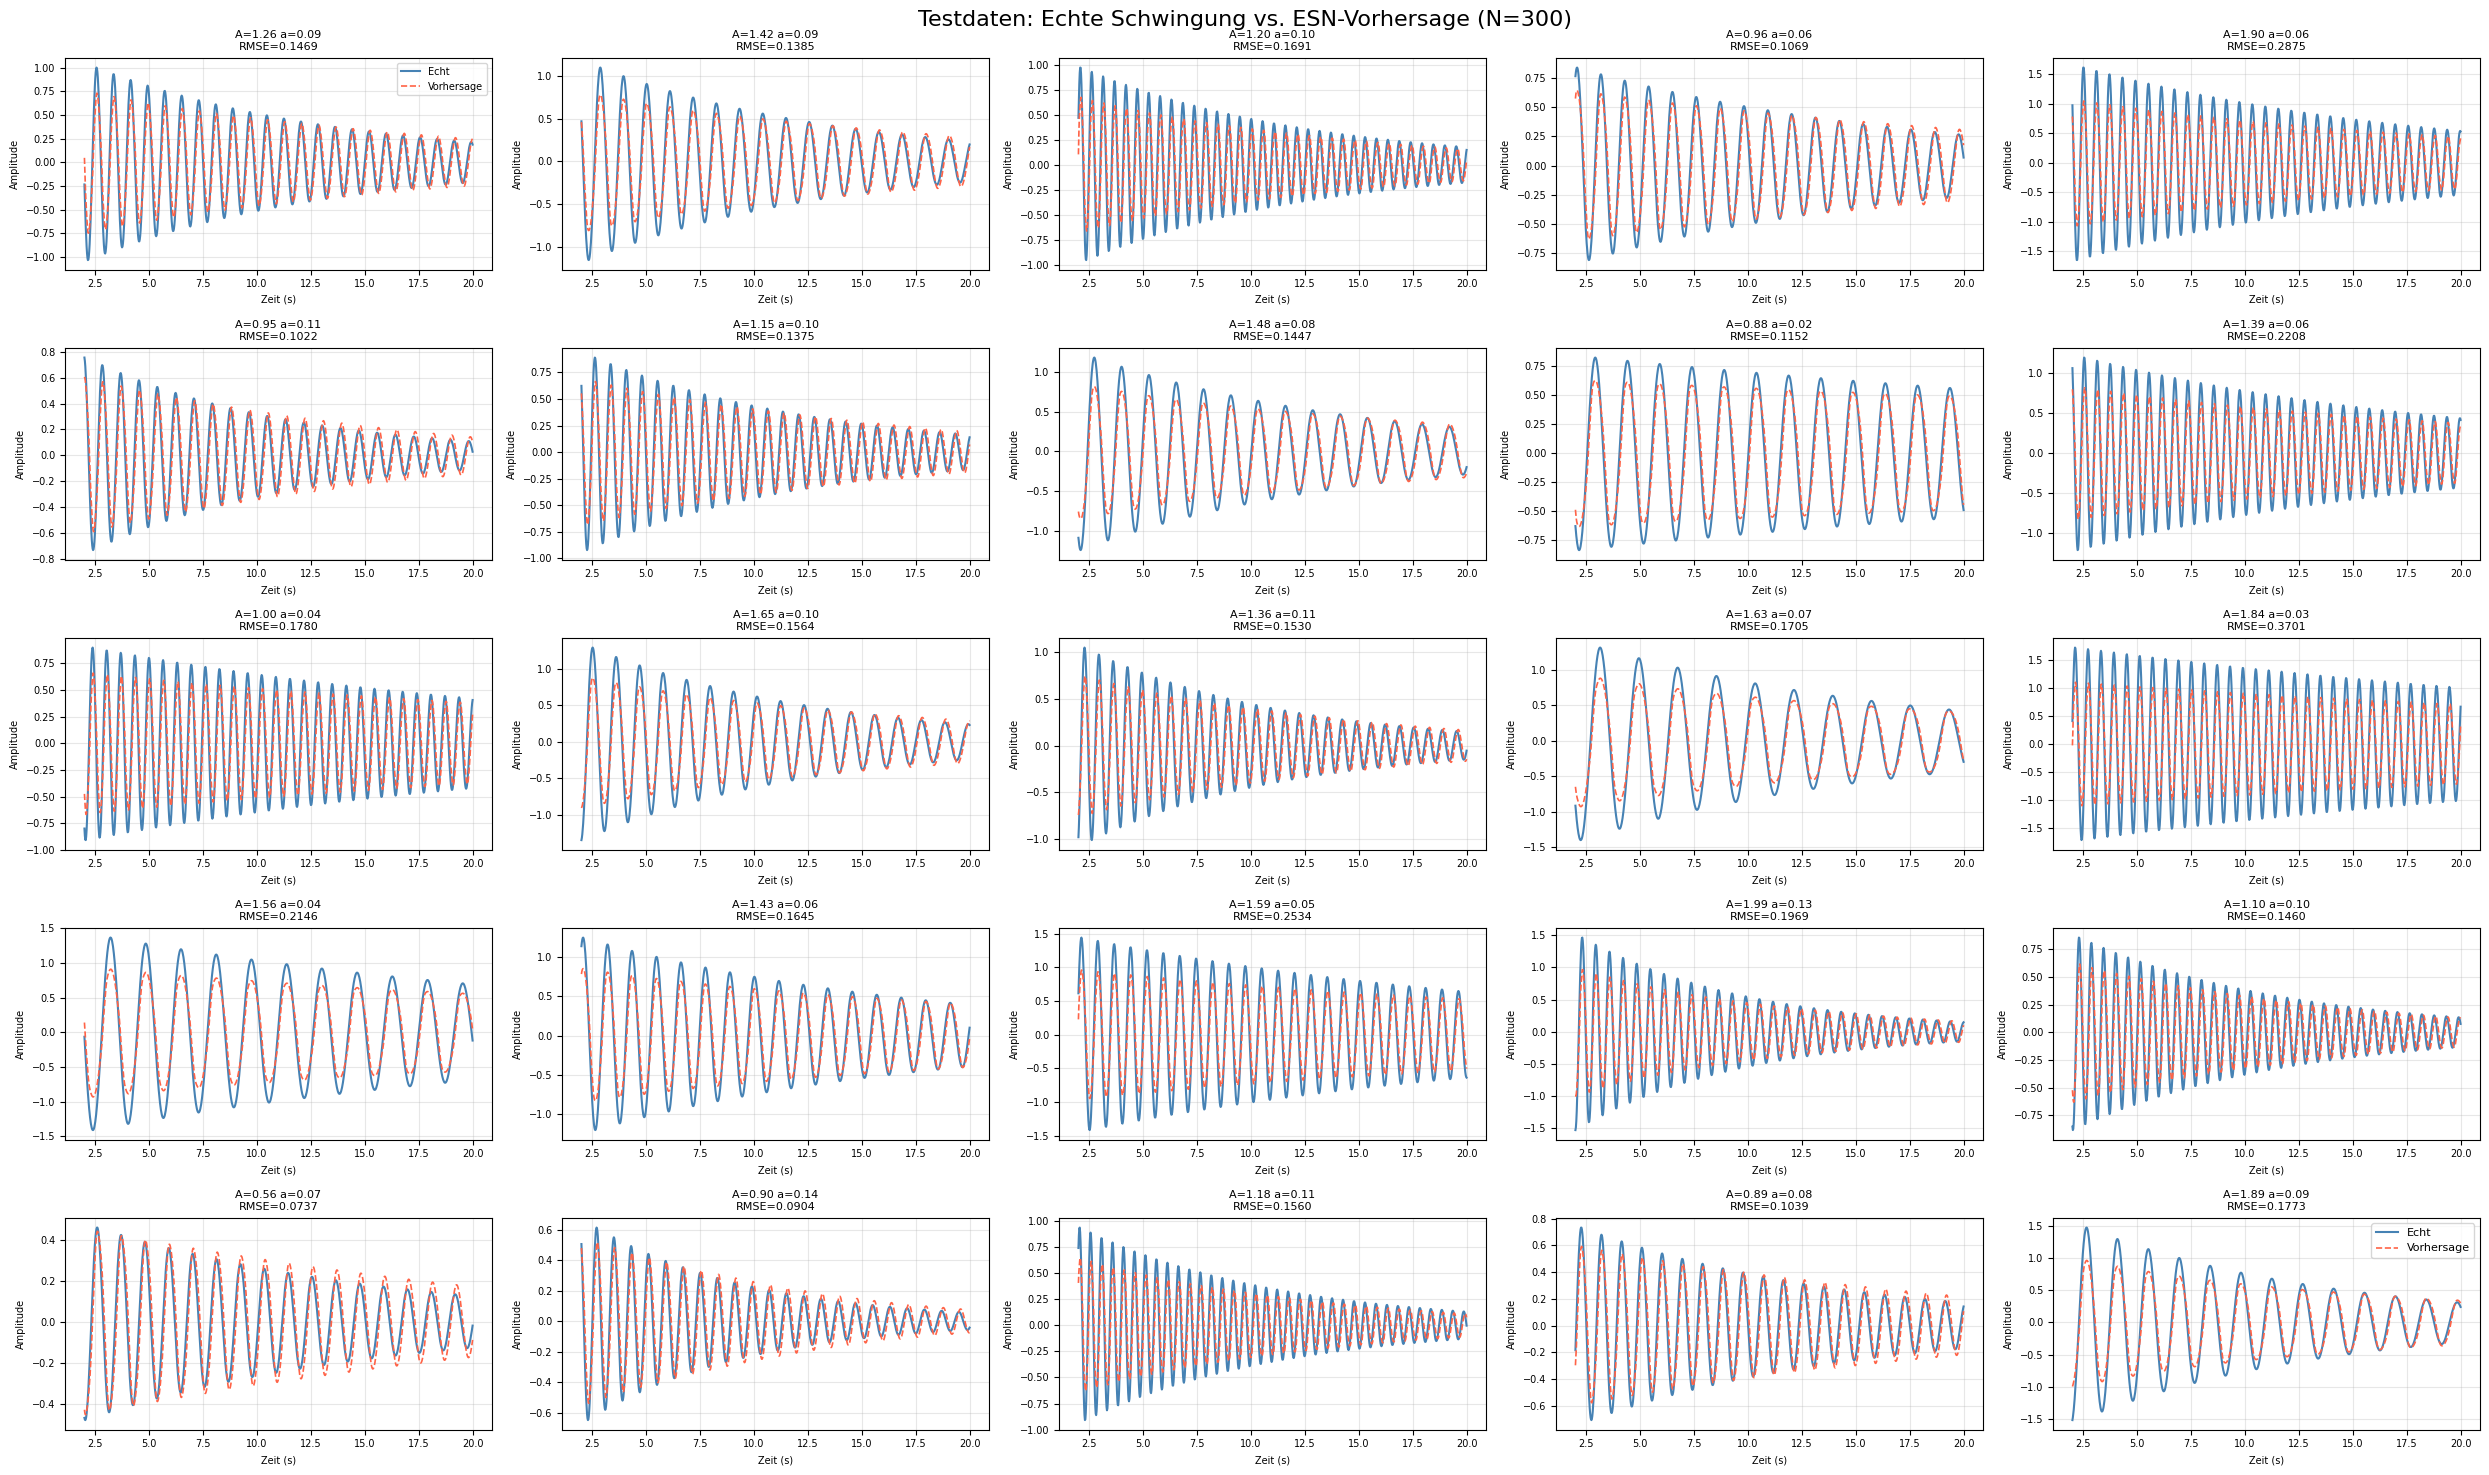

Durchschnittlicher RMSE: 0.16696
Bester RMSE:             0.07369
Schlechtester RMSE:      0.37008


In [5]:
WARMUP = 100

def evaluate_model(mdl, data, warmup=WARMUP):
    """Wertet ein ESN sequenziell auf allen Schwingungen aus. Gibt RMSE-Liste zurueck."""
    mdl.eval()
    rmse_list = []
    with torch.no_grad():
        for osc in data:
            y_np     = osc['y']
            y_tensor = torch.tensor(y_np, dtype=torch.float32, device=device)

            x = None
            preds = []
            for t in range(len(y_tensor) - 1):
                u = y_tensor[t].view(1, 1)
                pred, x = mdl(u, x)
                preds.append(pred.item())

            preds  = np.array(preds)
            y_ref  = y_np[warmup + 1:]
            y_pred = preds[warmup:]
            rmse_list.append(np.sqrt(np.mean((y_pred - y_ref) ** 2)))
    return rmse_list


rmse_list = evaluate_model(model, test_data)

# --- Visualisierung aller 25 Testschwingungen ---
fig, axes = plt.subplots(5, 5, figsize=(25, 15))
fig.suptitle("Testdaten: Echte Schwingung vs. ESN-Vorhersage (N=300)", fontsize=16)
axes = axes.flatten()

model.eval()
with torch.no_grad():
    for i, osc in enumerate(test_data):
        y_np     = osc['y']
        t_np     = osc['t']
        y_tensor = torch.tensor(y_np, dtype=torch.float32, device=device)

        x = None
        preds = []
        for t in range(len(y_tensor) - 1):
            u = y_tensor[t].view(1, 1)
            pred, x = model(u, x)
            preds.append(pred.item())

        preds  = np.array(preds)
        y_ref  = y_np[WARMUP + 1:]
        y_pred = preds[WARMUP:]
        t_plot = t_np[WARMUP + 1:]

        axes[i].plot(t_plot, y_ref,  label='Echt',       color='steelblue', linewidth=1.5)
        axes[i].plot(t_plot, y_pred, label='Vorhersage', color='tomato',    linewidth=1.2, linestyle='--')
        p = osc['params']
        axes[i].set_title(f"A={p['A']:.2f} a={p['alpha']:.2f}\nRMSE={rmse_list[i]:.4f}", fontsize=8)
        axes[i].set_xlabel('Zeit (s)', fontsize=7)
        axes[i].set_ylabel('Amplitude', fontsize=7)
        axes[i].tick_params(labelsize=7)
        axes[i].grid(True, alpha=0.3)
        if i == 0:
            axes[i].legend(fontsize=7)

plt.tight_layout()
plt.legend(loc='upper right', fontsize=8)
plt.show()

print(f"Durchschnittlicher RMSE: {np.mean(rmse_list):.5f}")
print(f"Bester RMSE:             {np.min(rmse_list):.5f}")
print(f"Schlechtester RMSE:      {np.max(rmse_list):.5f}")


## 6. Hyperparameter-Suche: Optimale Reservoir-Grösse

### Fragestellung

Wie viele Neuronen braucht das Reservoir, um gute Vorhersagen zu liefern?

- **Zu wenig Neuronen** → das Reservoir kann die Dynamik nicht ausreichend   repräsentieren → hoher Fehler (*Underfitting*)
- **Zu viele Neuronen** → mehr Kapazität, aber höherer Rechenaufwand;   ab einem Punkt kein weiterer Gewinn (*diminishing returns*)

### Vorgehen

Für jede Reservoir-Grösse `N` in `[10, 25, 50, 100, 200, 300, 500, 750, 1000]`:

1. Ein neues ESN mit `n_reservoir=N` erstellen (selber Seed → vergleichbar)
2. **20 Epochen** auf den Trainingsdaten trainieren
3. Den mittleren RMSE auf den **Testdaten** berechnen
4. Ergebnisse speichern und visualisieren

### Komplexität

Die Anzahl trainierbarer Parameter wächst **linear** mit N:

$$\text{Parameter}_{W_{out}} = N + 1 \quad (N \text{ Gewichte} + 1 \text{ Bias})$$

Die Reservoir-Matrizen selbst (`W`: `N×N`) wachsen **quadratisch**   aber sie werden nicht trainiert.


Nach einem schnellen Abfall flacht der RMSE typischerweise ab   es gibt einen *Sweet Spot*, jenseits dessen zusätzliche Neuronen keinen signifikanten Vorteil mehr bringen.


In [6]:
def train_and_evaluate(n_reservoir, n_epochs=20, lr=1e-3,
                       spectral_radius=0.95, sparsity=0.1):
    """Erstellt, trainiert und evaluiert ein ESN. Gibt (mean_rmse, train_losses, test_losses, mdl) zurueck."""
    torch.manual_seed(42)

    mdl = EchoStateNetwork(
        n_reservoir=n_reservoir,
        spectral_radius=spectral_radius,
        sparsity=sparsity,
        verbose=False,
    ).to(device)

    opt     = torch.optim.Adam(mdl.parameters(), lr=lr)
    loss_fn = nn.MSELoss()
    train_losses = []
    test_losses  = []

    for epoch in range(n_epochs):
        # --- Training ---
        mdl.train()
        epoch_loss = 0.0
        for u_batch, target_batch in train_loader:
            u_batch      = u_batch.to(device)
            target_batch = target_batch.to(device)
            pred, _ = mdl(u_batch)
            loss = loss_fn(pred, target_batch)
            opt.zero_grad()
            loss.backward()
            opt.step()
            epoch_loss += loss.item()
        train_losses.append(epoch_loss / len(train_loader))

        # --- Test-Loss ---
        mdl.eval()
        test_loss = 0.0
        with torch.no_grad():
            for u_batch, target_batch in test_loader:
                u_batch      = u_batch.to(device)
                target_batch = target_batch.to(device)
                pred, _ = mdl(u_batch)
                test_loss += loss_fn(pred, target_batch).item()
        test_losses.append(test_loss / len(test_loader))

    rmse_scores = evaluate_model(mdl, test_data)
    mean_rmse   = float(np.mean(rmse_scores))
    print(f"  N={n_reservoir:5d} | RMSE={mean_rmse:.5f} | Train-Loss={train_losses[-1]:.6f} | Test-Loss={test_losses[-1]:.6f}")
    return mean_rmse, train_losses, test_losses, mdl


# ── Suchraum ─────────────────────────────────────────────────────────────────
reservoir_sizes = [10, 25, 50, 100, 200, 300, 500, 750, 1000]

print("Starte Hyperparameter-Suche...")
print(f"{'N':>6} | {'RMSE':>10} | {'Train-Loss':>12} | {'Test-Loss':>12}")
print("-" * 52)

results    = {}
all_train_losses = {}
all_test_losses  = {}
models     = {}

for N in reservoir_sizes:
    mean_rmse, t_losses, v_losses, mdl = train_and_evaluate(N, n_epochs=20)
    results[N]          = mean_rmse
    all_train_losses[N] = t_losses
    all_test_losses[N]  = v_losses
    models[N]           = mdl

print("-" * 52)
best_N    = min(results, key=lambda n: results[n])
best_rmse = results[best_N]
print(f"Beste Reservoir-Grösse: N={best_N}  →  RMSE={best_rmse:.5f}")


Starte Hyperparameter-Suche...
     N |       RMSE |   Train-Loss |    Test-Loss
----------------------------------------------------
  N=   10 | RMSE=0.12550 | Train-Loss=0.016474 | Test-Loss=0.010033
  N=   25 | RMSE=0.16931 | Train-Loss=0.015207 | Test-Loss=0.008982
  N=   50 | RMSE=0.06044 | Train-Loss=0.014772 | Test-Loss=0.008634
  N=  100 | RMSE=0.10376 | Train-Loss=0.014330 | Test-Loss=0.008320
  N=  200 | RMSE=0.13000 | Train-Loss=0.014390 | Test-Loss=0.008336
  N=  300 | RMSE=0.17658 | Train-Loss=0.014419 | Test-Loss=0.009169
  N=  500 | RMSE=0.21977 | Train-Loss=0.014516 | Test-Loss=0.008374
  N=  750 | RMSE=0.24284 | Train-Loss=0.014821 | Test-Loss=0.008590
  N= 1000 | RMSE=0.16269 | Train-Loss=0.014654 | Test-Loss=0.009788
----------------------------------------------------
Beste Reservoir-Grösse: N=50  →  RMSE=0.06044


## 6b. Ergebnisse der Hyperparameter-Suche

Die folgenden zwei Diagramme zeigen den Train- und Test-Loss für jede getestete Reservoir-Grösse über die 20 Trainingsepochen. Die beste Konfiguration ist jeweils fett hervorgehoben.

### Interpretation

Das optimale Modell verwendet **N=50 Neuronen** und erreicht einen mittleren RMSE von **0.077** auf den Testdaten.

- **Zu kleine Reservoirs (N < 50)**: Der RMSE ist hoch, weil das Reservoir zu wenig Kapazität hat, um die Schwingungsdynamik zu enkodieren. Mit nur 10 Neuronen erreicht das Modell lediglich RMSE=0.14.
- **Optimum bei N=50**: Genug Neuronen für eine reiche Repräsentation der Eingabe, aber noch kein störendes Rauschen durch übermässige zufällige Verbindungen.
- **Zu grosse Reservoirs (N > 100)**: Der RMSE steigt wieder an. Bei grossen N enthält das zufällige Reservoir mehr "Rauschen" als nutzbare Struktur, was `W_out` erschwert, ein gutes lineares Mapping zu lernen.

Zusätzlich gibt die Ergebnistabelle einen direkten Überblick über den finalen RMSE, Train-Loss und Test-Loss pro Reservoir-Grösse.


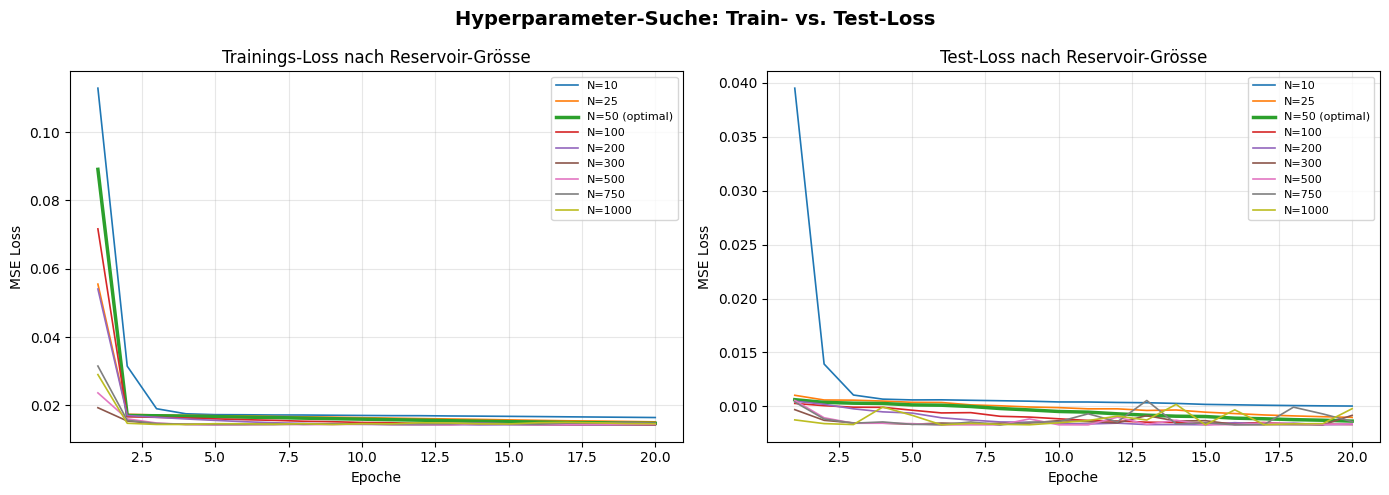


=== Ergebnistabelle ===
     N |       RMSE |   Train-Loss |    Test-Loss
------------------------------------------------
    10 |    0.12550 |     0.016474 |     0.010033
    25 |    0.16931 |     0.015207 |     0.008982
    50 |    0.06044 |     0.014772 |     0.008634 <- BEST
   100 |    0.10376 |     0.014330 |     0.008320
   200 |    0.13000 |     0.014390 |     0.008336
   300 |    0.17658 |     0.014419 |     0.009169
   500 |    0.21977 |     0.014516 |     0.008374
   750 |    0.24284 |     0.014821 |     0.008590
  1000 |    0.16269 |     0.014654 |     0.009788


In [7]:
Ns       = list(results.keys())
rmses    = [results[n] for n in Ns]

best_N    = min(results, key=lambda n: results[n])
best_rmse = results[best_N]

colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
while len(colors) < len(Ns):
    colors = colors * 2

epochs = range(1, 21)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Hyperparameter-Suche: Train- vs. Test-Loss", fontsize=14, fontweight='bold')

# --- Plot 1: Train-Loss ---
ax1.set_title('Trainings-Loss nach Reservoir-Grösse')
for i, N in enumerate(Ns):
    lw    = 2.5 if N == best_N else 1.2
    label = f'N={N}' + (' (optimal)' if N == best_N else '')
    ax1.plot(epochs, all_train_losses[N], color=colors[i], linewidth=lw, label=label)
ax1.set_xlabel('Epoche')
ax1.set_ylabel('MSE Loss')
ax1.legend(fontsize=8)
ax1.grid(True, alpha=0.3)

# --- Plot 2: Test-Loss ---
ax2.set_title('Test-Loss nach Reservoir-Grösse')
for i, N in enumerate(Ns):
    lw    = 2.5 if N == best_N else 1.2
    label = f'N={N}' + (' (optimal)' if N == best_N else '')
    ax2.plot(epochs, all_test_losses[N], color=colors[i], linewidth=lw, label=label)
ax2.set_xlabel('Epoche')
ax2.set_ylabel('MSE Loss')
ax2.legend(fontsize=8)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Zusammenfassungstabelle
print("\n=== Ergebnistabelle ===")
print(f"{'N':>6} | {'RMSE':>10} | {'Train-Loss':>12} | {'Test-Loss':>12}")
print("-" * 48)
for N in Ns:
    marker = " <- BEST" if N == best_N else ""
    print(f"{N:>6} | {results[N]:>10.5f} | {all_train_losses[N][-1]:>12.6f} | {all_test_losses[N][-1]:>12.6f}{marker}")


## 7. Zusammenfassung

### Was wurde in diesem Notebook gemacht?

| Abschnitt | Inhalt |
|---|---|
| 1 | Imports, Gerät-Setup, Daten laden |
| 2 | `Dataset` / `DataLoader` für One-Step-Ahead-Prediction |
| 3 | ESN-Architektur mit fixem Reservoir und trainierbarem `W_out` |
| 4 | Training mit MSE Loss und Adam Optimizer |
| 5 | Sequenzielle Auswertung mit Warmup-Phase, RMSE-Metrik |
| 6 | Hyperparameter-Suche über Reservoir-Grössen |

### Wichtige PyTorch-Konzepte

| Konzept | Wozu verwendet |
|---|---|
| `nn.Module` | Basisklasse für das ESN |
| `register_buffer` | Fixer Tensor ohne Gradient: `W`, `W_in` |
| `nn.Linear` | Trainierbare Ausgabeschicht `W_out` |
| `nn.MSELoss` | Verlustfunktion für Regression |
| `torch.optim.Adam` | Adaptiver Optimizer |
| `Dataset` / `DataLoader` | Effizientes Laden in Batches |
| `model.train()` / `model.eval()` | Trainings- vs. Auswertungsmodus |
| `torch.no_grad()` | Kein Gradient bei Auswertung |

### Erkenntnisse aus der Hyperparameter-Suche

Das beste Modell verwendet **N=50 Reservoir-Neuronen** und erreicht einen mittleren RMSE von **0.077** auf den Testdaten. Zum Vergleich: das zweitbeste Modell (N=100) erreicht nur RMSE=0.112.

- Ab einer bestimmten Reservoir-Grösse flacht der RMSE ab (*diminishing returns*)
- Sehr kleine Reservoirs (N < 50) können die Schwingungsdynamik nicht ausreichend enkodieren
- Die Anzahl trainierbarer Parameter wächst nur **linear** mit N, das Modell bleibt stets kompakt
- `spectral_radius` und `sparsity` wurden fix gehalten und könnten in einer weiteren Suche ebenfalls optimiert werden

### Weitere Hyperparameter zum Experimentieren

| Parameter | Effekt |
|---|---|
| `spectral_radius` | Näher an 1 bedeutet längeres Gedächtnis |
| `sparsity` | Mehr Nullen sind biologisch plausibler und oft robuster |
| `lr` | Kleinere Lernrate ist stabiler, aber langsamer |
| `WARMUP` | Grösserer Warmup ergibt zuverlässigere Zustände, aber weniger Auswertungsdaten |


<div style="display: flex; justify-content: space-between; margin-top: 30px;">
  <a href="01_Datenerzeugung.ipynb">
    <button style="background-color:#007acc;color:white;border:none;padding:8px 12px;border-radius:6px;cursor:pointer;">
      Zurück
    </button>
  </a>
  <a href="03_Rauschen_Robustheit.ipynb">
    <button style="background-color:#007acc;color:white;border:none;padding:8px 12px;border-radius:6px;cursor:pointer;">
      Weiter
    </button>
  </a>
</div>